# LAB 4 – Encoder–Decoder và Attention (Anh → Việt)

**Bài 1:** Encoder–Decoder LSTM

**Bài 2:** Bahdanau Attention

**Bài 3:** Luong General Attention.

## 1. Thư viện và cấu hình

In [1]:
!pip -q install gdown rouge-score sacrebleu

In [2]:
import json, random, time, unicodedata
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader
from rouge_score import rouge_scorer
from sacrebleu.metrics import BLEU

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Thiết bị:', device)

cfg = dict(emb=256, hidden=256, layers=3, dropout=0.3,
           batch=32, lr=1e-3, teacher_ratio=0.5, epochs=10,
           max_words=50, vocab_limit=10000, min_freq=2)
PAD, UNK, BOS, EOS = 0, 1, 2, 3
ART = Path('/kaggle/working/artifacts')
ART.mkdir(exist_ok=True)

Thiết bị: cuda


## 2. Tải dữ liệu small-PhoMT và tiền xử lý

In [3]:
from pathlib import Path

DATA = Path('/kaggle/input/datasets/danvi12/phomt-dataset')

files = {
    split: DATA / f'small-{split}.json'
    for split in ['train', 'dev', 'test']
}

print(files)
assert all(p.is_file() for p in files.values()), 'Không tìm thấy file JSON'

print("Đủ 3 file JSON!")

{'train': PosixPath('/kaggle/input/datasets/danvi12/phomt-dataset/small-train.json'), 'dev': PosixPath('/kaggle/input/datasets/danvi12/phomt-dataset/small-dev.json'), 'test': PosixPath('/kaggle/input/datasets/danvi12/phomt-dataset/small-test.json')}
Đủ 3 file JSON!


In [4]:
def tokens(s):
    return unicodedata.normalize('NFC', s.lstrip('\ufeff')).lower().split()

filtered = {}
for split, path in files.items():
    rows = json.loads(path.read_text(encoding='utf-8-sig'))
    filtered[split] = []
    for i, row in enumerate(rows):
        src, tgt = tokens(row['english']), tokens(row['vietnamese'])
        if 1 <= len(src) <= cfg['max_words'] and 1 <= len(tgt) <= cfg['max_words']:
            filtered[split].append(dict(id=i, src=src, tgt=tgt))
    print(split, 'gốc:', len(rows), '| sau lọc:', len(filtered[split]))

train gốc: 20000 | sau lọc: 18607
dev gốc: 2000 | sau lọc: 1901
test gốc: 2000 | sau lọc: 1786


## 3. Từ điển, batch và DataLoader

In [5]:
SPECIAL = ['<pad>', '<unk>', '<bos>', '<eos>']
def make_vocab(sequences):
    freq = Counter(t for seq in sequences for t in seq)
    words = sorted(freq, key=lambda t: (-freq[t], t))
    words = [t for t in words if freq[t] >= cfg['min_freq'] and t not in SPECIAL]
    return {t: i for i, t in enumerate(SPECIAL + words[:cfg['vocab_limit']-4])}

src_vocab = make_vocab(r['src'] for r in filtered['train'])
tgt_vocab = make_vocab(r['tgt'] for r in filtered['train'])
tgt_itos = {i: t for t, i in tgt_vocab.items()}

def encode(words, vocab):
    return [vocab.get(w, UNK) for w in words]

def collate(rows):
    src = [torch.tensor(encode(r['src'], src_vocab) + [EOS]) for r in rows]
    tgt = [torch.tensor([BOS] + encode(r['tgt'], tgt_vocab) + [EOS]) for r in rows]
    return dict(src=pad_sequence(src, batch_first=True, padding_value=PAD),
                lengths=torch.tensor([len(x) for x in src]),
                tgt=pad_sequence(tgt, batch_first=True, padding_value=PAD),
                refs=[' '.join(r['tgt']) for r in rows],
                source=[' '.join(r['src']) for r in rows])

def loader(rows, shuffle=False):
    return DataLoader(rows, batch_size=cfg['batch'], shuffle=shuffle,
                      collate_fn=collate, generator=torch.Generator().manual_seed(42))

print('Số từ Anh:', len(src_vocab), '| số từ Việt:', len(tgt_vocab))

Số từ Anh: 8943 | số từ Việt: 4003


## 4. Encoder LSTM

In [6]:
class Encoder(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, cfg['emb'], padding_idx=PAD)
        self.drop = nn.Dropout(cfg['dropout'])
        self.lstm = nn.LSTM(cfg['emb'], cfg['hidden'], cfg['layers'], batch_first=True,
                            dropout=cfg['dropout'])

    def forward(self, src, lengths):
        x = self.drop(self.emb(src))
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True,
                                      enforce_sorted=False)
        out, state = self.lstm(packed)
        memory, _ = pad_packed_sequence(out, batch_first=True,
                                       total_length=src.size(1))
        return memory, state

## 5. Bahdanau Attention và Luong General Attention

In [7]:
class Attention(nn.Module):
    def __init__(self, mode):
        super().__init__()
        self.mode = mode
        if mode == 'bahdanau':
            self.Wq = nn.Linear(cfg['hidden'], cfg['hidden'], bias=False)
            self.Wk = nn.Linear(cfg['hidden'], cfg['hidden'], bias=False)
            self.v = nn.Linear(cfg['hidden'], 1, bias=False)
        elif mode == 'luong':
            self.W = nn.Linear(cfg['hidden'], cfg['hidden'], bias=False)

    def forward(self, query, memory, mask):
        if self.mode == 'bahdanau':
            scores = self.v(torch.tanh(self.Wq(query).unsqueeze(1)
                                       + self.Wk(memory))).squeeze(-1)
        else:
            scores = torch.bmm(self.W(memory), query.unsqueeze(2)).squeeze(2)
        scores = scores.masked_fill(~mask, float('-inf'))
        weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(weights.unsqueeze(1), memory).squeeze(1)
        return context, weights

## 6. Decoder và mô hình Seq2Seq (dùng chung cho 3 bài)

In [8]:
class Decoder(nn.Module):
    def __init__(self, vocab_size, mode):
        super().__init__()
        self.mode = mode
        self.emb = nn.Embedding(vocab_size, cfg['emb'], padding_idx=PAD)
        self.drop = nn.Dropout(cfg['dropout'])
        width = cfg['emb'] if mode == 'none' else cfg['emb'] + cfg['hidden']
        self.lstm = nn.LSTM(width, cfg['hidden'], cfg['layers'], batch_first=True,
                            dropout=cfg['dropout'])
        if mode != 'none':
            self.attn = Attention(mode)
            self.fuse = nn.Linear(2 * cfg['hidden'], cfg['hidden'])
        self.fc = nn.Linear(cfg['hidden'], vocab_size)

    def step(self, token, state, memory, mask, feeding):
        x = self.drop(self.emb(token))
        weights = None
        if self.mode == 'bahdanau':
            context, weights = self.attn(state[0][-1], memory, mask)
            x = torch.cat([x, context], dim=-1)
        elif self.mode == 'luong':
            x = torch.cat([x, feeding], dim=-1)
        out, state = self.lstm(x.unsqueeze(1), state)
        query = out[:, 0]
        if self.mode == 'luong':
            context, weights = self.attn(query, memory, mask)
        if self.mode != 'none':
            feeding = torch.tanh(self.fuse(torch.cat([query, context], dim=-1)))
            query = feeding
        return self.fc(self.drop(query)), state, feeding, weights

class Seq2Seq(nn.Module):
    def __init__(self, mode):
        super().__init__()
        self.mode = mode
        self.encoder = Encoder(len(src_vocab))
        self.decoder = Decoder(len(tgt_vocab), mode)

    def forward(self, src, lengths, tgt, teacher_ratio=0.5):
        memory, state = self.encoder(src, lengths)
        mask = src != PAD
        token = tgt[:, 0]
        feeding = memory.new_zeros(src.size(0), cfg['hidden'])
        outputs = []
        for t in range(1, tgt.size(1)):
            pred, state, feeding, _ = self.decoder.step(token, state, memory, mask, feeding)
            outputs.append(pred)
            coin = torch.rand(src.size(0), device=src.device)
            token = torch.where(coin < teacher_ratio, tgt[:, t], pred.argmax(-1).detach())
        return torch.stack(outputs, dim=1)

## 7. Giải mã greedy và ROUGE-L

In [9]:
@torch.no_grad()
def generate(model, src, lengths, max_steps=51):
    model.eval()
    memory, state = model.encoder(src, lengths)
    mask = src != PAD
    token = torch.full((src.size(0),), BOS, device=src.device)
    feeding = memory.new_zeros(src.size(0), cfg['hidden'])
    finished = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    outputs, attn = [], []
    for _ in range(max_steps):
        logits, state, feeding, weights = model.decoder.step(token, state, memory, mask, feeding)
        logits[:, [PAD, BOS]] = float('-inf')
        token = logits.argmax(-1)
        token = torch.where(finished, torch.full_like(token, EOS), token)
        outputs.append(token)
        if weights is not None: attn.append(weights)
        finished |= token == EOS
        if bool(finished.all()): break
    ids = torch.stack(outputs, dim=1)
    weights = torch.stack(attn, dim=1) if attn else None
    return ids, weights

def decode(ids):
    words = []
    for i in ids:
        i = int(i)
        if i == EOS: break
        if i not in (PAD, BOS): words.append(tgt_itos[i])
    return ' '.join(words)

class UnicodeTokens:
    def tokenize(self, text): return tokens(text)

rouge = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=False,
                                 tokenizer=UnicodeTokens())
def translation_metrics(hypotheses, references):
    f1 = [rouge.score(ref, hyp)['rougeL'].fmeasure
          for hyp, ref in zip(hypotheses, references)]
    bleu = BLEU(tokenize='none').corpus_score(hypotheses, [references]).score
    return dict(rougeL_f1=float(np.mean(f1)), bleu=bleu)

@torch.no_grad()
def evaluate(model, rows):
    model.eval()
    hypotheses, references = [], []
    nll, n_tokens = 0., 0
    for b in loader(rows):
        src, tgt = b['src'].to(device), b['tgt'].to(device)
        gold = tgt[:, 1:]
        logits = model(src, b['lengths'], tgt, teacher_ratio=1.0)
        nll += nn.functional.cross_entropy(logits.reshape(-1, len(tgt_vocab)),
                  gold.reshape(-1), ignore_index=PAD, reduction='sum').item()
        n_tokens += (gold != PAD).sum().item()
        ids, _ = generate(model, src, b['lengths'], cfg['max_words'] + 1)
        hypotheses.extend(decode(row) for row in ids.cpu())
        references.extend(b['refs'])
    result = translation_metrics(hypotheses, references)
    result['nll'] = nll / n_tokens
    return result

## 8. Huấn luyện, chọn checkpoint tốt nhất bằng ROUGE-L dev

In [10]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD)

def train_epoch(model, optimizer):
    model.train()
    total_loss, n_tokens = 0., 0
    for b in loader(filtered['train'], shuffle=True):
        src, tgt = b['src'].to(device), b['tgt'].to(device)
        optimizer.zero_grad()
        logits = model(src, b['lengths'], tgt, cfg['teacher_ratio'])
        gold = tgt[:, 1:]
        loss = criterion(logits.reshape(-1, len(tgt_vocab)), gold.reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        count = (gold != PAD).sum().item()
        total_loss += loss.item() * count
        n_tokens += count
    return total_loss / n_tokens

def fit(model, name):
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    history, best_score, best_nll, best_epoch = [], -1., float('inf'), 0
    for epoch in range(1, cfg['epochs'] + 1):
        start = time.perf_counter()
        train_loss = train_epoch(model, optimizer)
        if device.type == 'cuda': torch.cuda.synchronize()
        seconds = time.perf_counter() - start
        score = evaluate(model, filtered['dev'])
        history.append(dict(epoch=epoch, train_loss=train_loss, seconds=seconds,
                            dev_rougeL=score['rougeL_f1'], dev_bleu=score['bleu']))
        if score['rougeL_f1'] > best_score or (score['rougeL_f1'] == best_score and score['nll'] < best_nll):
            best_score, best_nll, best_epoch = score['rougeL_f1'], score['nll'], epoch
            torch.save(model.state_dict(), ART / f'{name}.pt')
        print(f'{name} | epoch {epoch}: loss={train_loss:.4f}, '
              f'dev ROUGE-L={score["rougeL_f1"]:.4f}, BLEU={score["bleu"]:.2f}')
    model.load_state_dict(torch.load(ART / f'{name}.pt', map_location=device, weights_only=True))
    return pd.DataFrame(history), best_epoch

## 9. Bài 1 – Encoder–Decoder không Attention

In [11]:
torch.manual_seed(42)
models, histories, best_epochs = {}, {}, {}
model = Seq2Seq('none').to(device)
histories['none'], best_epochs['none'] = fit(model, 'none')
models['none'] = model

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none | epoch 1: loss=6.0212, dev ROUGE-L=0.1300, BLEU=0.08


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none | epoch 2: loss=5.7196, dev ROUGE-L=0.1640, BLEU=0.52


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none | epoch 3: loss=5.5307, dev ROUGE-L=0.1730, BLEU=0.93


... (10 outputs left out)

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none | epoch 9: loss=4.9615, dev ROUGE-L=0.2242, BLEU=2.04


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none | epoch 10: loss=4.9015, dev ROUGE-L=0.2299, BLEU=2.19


## 10. Bài 2 – Bahdanau Attention

In [12]:
torch.manual_seed(42)
model = Seq2Seq('bahdanau').to(device)
histories['bahdanau'], best_epochs['bahdanau'] = fit(model, 'bahdanau')
models['bahdanau'] = model

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau | epoch 1: loss=6.0429, dev ROUGE-L=0.1366, BLEU=0.13


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau | epoch 2: loss=5.6521, dev ROUGE-L=0.1939, BLEU=1.21


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau | epoch 3: loss=5.3612, dev ROUGE-L=0.2194, BLEU=1.62


... (10 outputs left out)

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau | epoch 9: loss=4.5681, dev ROUGE-L=0.2882, BLEU=4.11


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau | epoch 10: loss=4.4828, dev ROUGE-L=0.2918, BLEU=4.44


## 11. Bài 3 – Luong General Attention

In [13]:
torch.manual_seed(42)
model = Seq2Seq('luong').to(device)
histories['luong'], best_epochs['luong'] = fit(model, 'luong')
models['luong'] = model

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong | epoch 1: loss=6.0672, dev ROUGE-L=0.1234, BLEU=0.11


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong | epoch 2: loss=5.7130, dev ROUGE-L=0.1841, BLEU=1.02


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong | epoch 3: loss=5.4266, dev ROUGE-L=0.2124, BLEU=1.50


... (10 outputs left out)

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong | epoch 9: loss=4.5905, dev ROUGE-L=0.2963, BLEU=4.38


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong | epoch 10: loss=4.5011, dev ROUGE-L=0.2985, BLEU=4.72


## 12. Đồ thị huấn luyện và bảng so sánh trên Dev

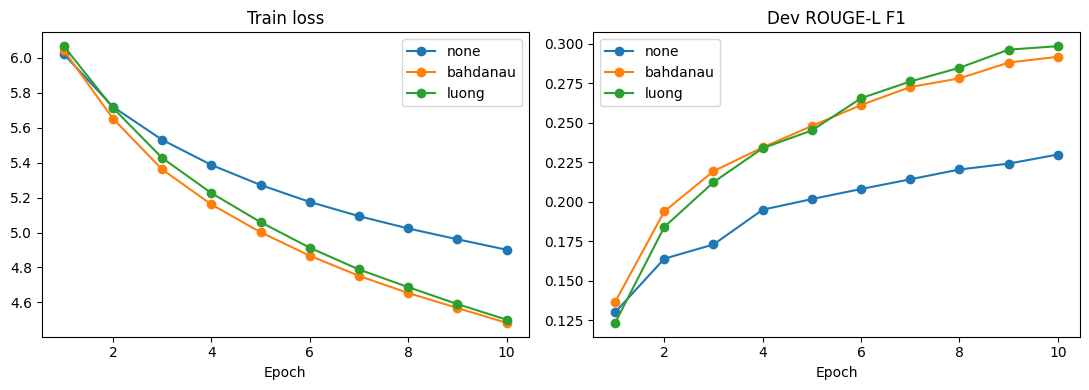

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


,model,rougeL_dev,best_epoch,parameters,seconds_per_epoch
0,none,0.2299,10,7500963,65.1827
1,bahdanau,0.2918,10,8025763,105.0444
2,luong,0.2985,10,7959971,98.3446


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, hist in histories.items():
    axes[0].plot(hist['epoch'], hist['train_loss'], marker='o', label=name)
    axes[1].plot(hist['epoch'], hist['dev_rougeL'], marker='o', label=name)
axes[0].set_title('Train loss')
axes[1].set_title('Dev ROUGE-L F1')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.legend()
plt.tight_layout()
plt.savefig(ART / 'learning_curves.png', dpi=150)
plt.show()

comparison = []
for name, model in models.items():
    result = evaluate(model, filtered['dev'])
    comparison.append(dict(model=name, rougeL_dev=result['rougeL_f1'],
                           best_epoch=best_epochs[name],
                           parameters=sum(p.numel() for p in model.parameters()),
                           seconds_per_epoch=histories[name]['seconds'].mean()))
comparison = pd.DataFrame(comparison)
display(comparison.round(4))
comparison.to_csv(ART / 'comparison_dev.csv', index=False)

## 13. Chấm Test một lần, sau khi đã chọn checkpoint bằng Dev

In [15]:
test_rows = []
for name, model in models.items():
    score = evaluate(model, filtered['test'])
    test_rows.append(dict(model=name, rougeL_test=score['rougeL_f1'], bleu_test=score['bleu']))
comparison_test = pd.DataFrame(test_rows)
comparison = comparison.merge(comparison_test, on='model')
display(comparison.round(4))
comparison.to_csv(ART / 'comparison_test.csv', index=False)

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


,model,rougeL_dev,best_epoch,parameters,seconds_per_epoch,rougeL_test,bleu_test
0,none,0.2299,10,7500963,65.1827,0.2354,2.6874
1,bahdanau,0.2918,10,8025763,105.0444,0.3046,5.4045
2,luong,0.2985,10,7959971,98.3446,0.3093,5.6128


## 14. Ba câu dịch mẫu (đúng/sai) và heatmap Attention

In [16]:
# Lấy ba câu test cố định; xuất câu dịch của cả ba mô hình để nhận xét.
examples = []
for row in filtered['test'][:3]:
    b = collate([row])
    source, reference = ' '.join(row['src']), ' '.join(row['tgt'])
    record = dict(source=source, reference=reference)
    for name, model in models.items():
        ids, _ = generate(model, b['src'].to(device), b['lengths'], cfg['max_words'] + 1)
        record[name] = decode(ids[0].cpu())
    examples.append(record)
examples_df = pd.DataFrame(examples)
display(examples_df)
examples_df.to_csv(ART / 'translations.csv', index=False)

,source,reference,none,bahdanau,luong
0,"brother albert barnett and his wife , sister s...","anh albert barnett và chị susan barnett , thuộ...","domitia <unk> , , , , , , , , , , , , , và <un...","ông bé <unk> , và cô gái , cô ấy , , , , , <un...","em em đã và và , , , , , , , , , , , , <unk> ,..."
1,severe storms ripped through parts of the sout...,"ngày 11 và 12-1-2020 , những cơn bão lớn đã qu...",những người của là là <unk> <unk> và và và và ...,sự <unk> <unk> <unk> <unk> <unk> trong trong t...,những là <unk> <unk> <unk> <unk> trong trên cá...
2,"two days of heavy rain , high winds , and nume...",những trận mưa to và gió lớn trong suốt hai ng...,"trong năm năm , , , , , , , , , , , , và và và...","hai hai hai người <unk> , , , , , , , và và và...","hai ngày khác , , , , , , , , , và và và <unk>..."


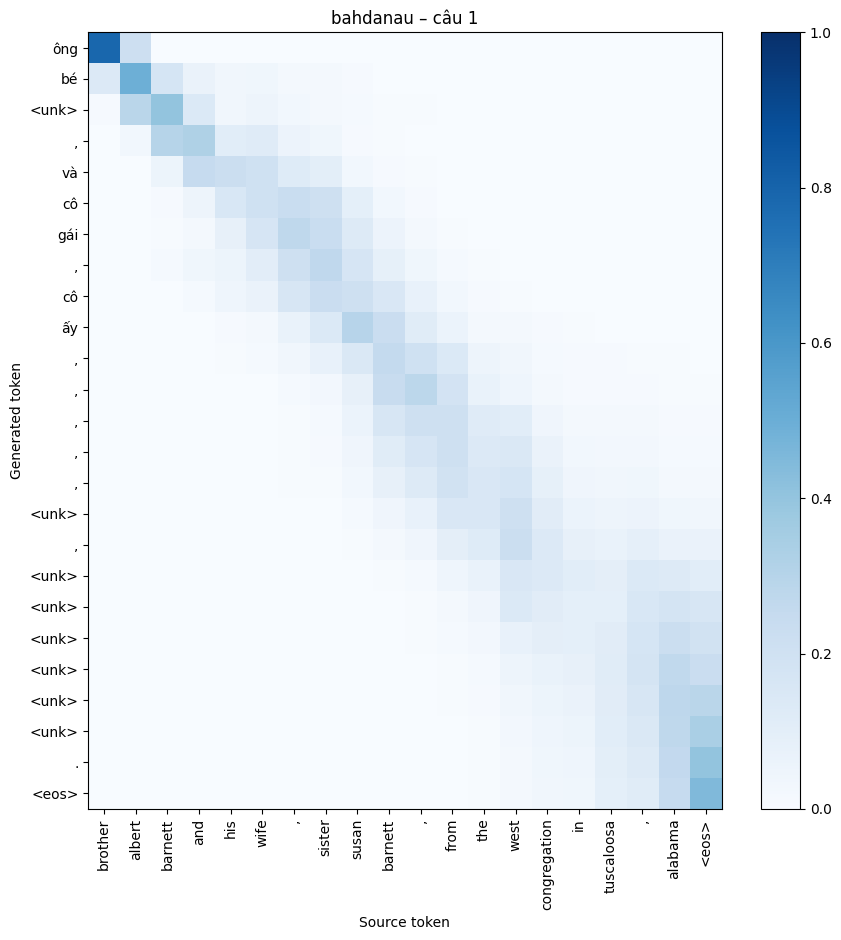

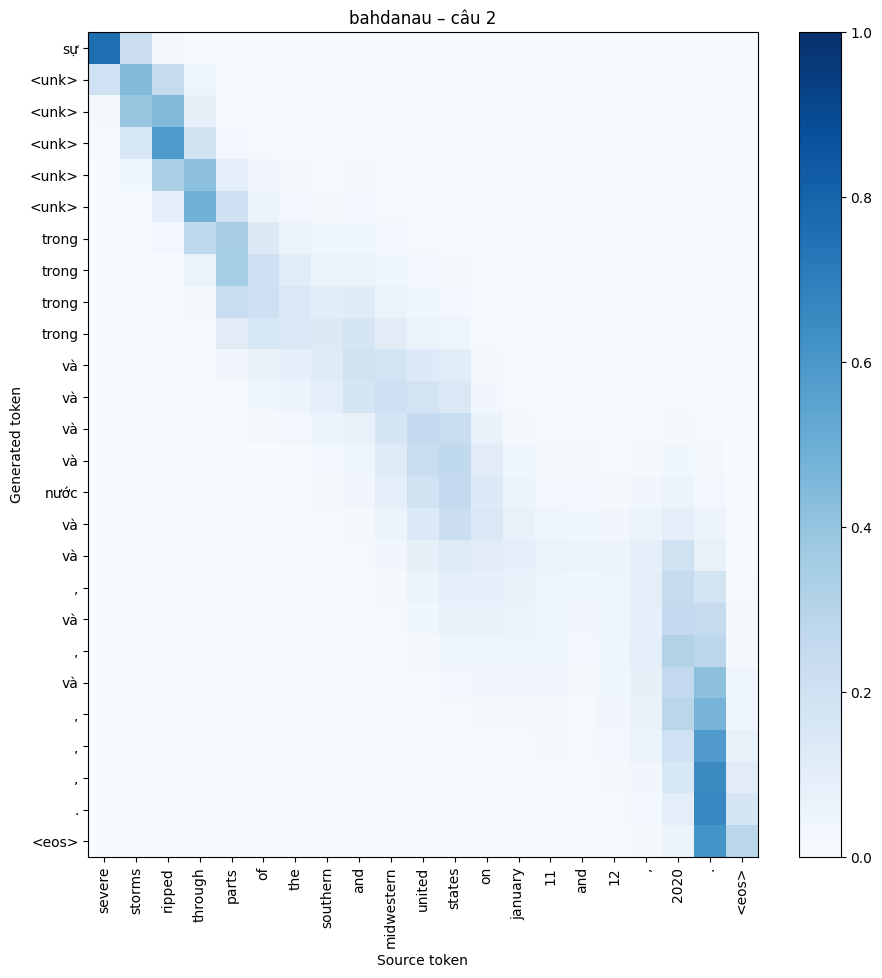

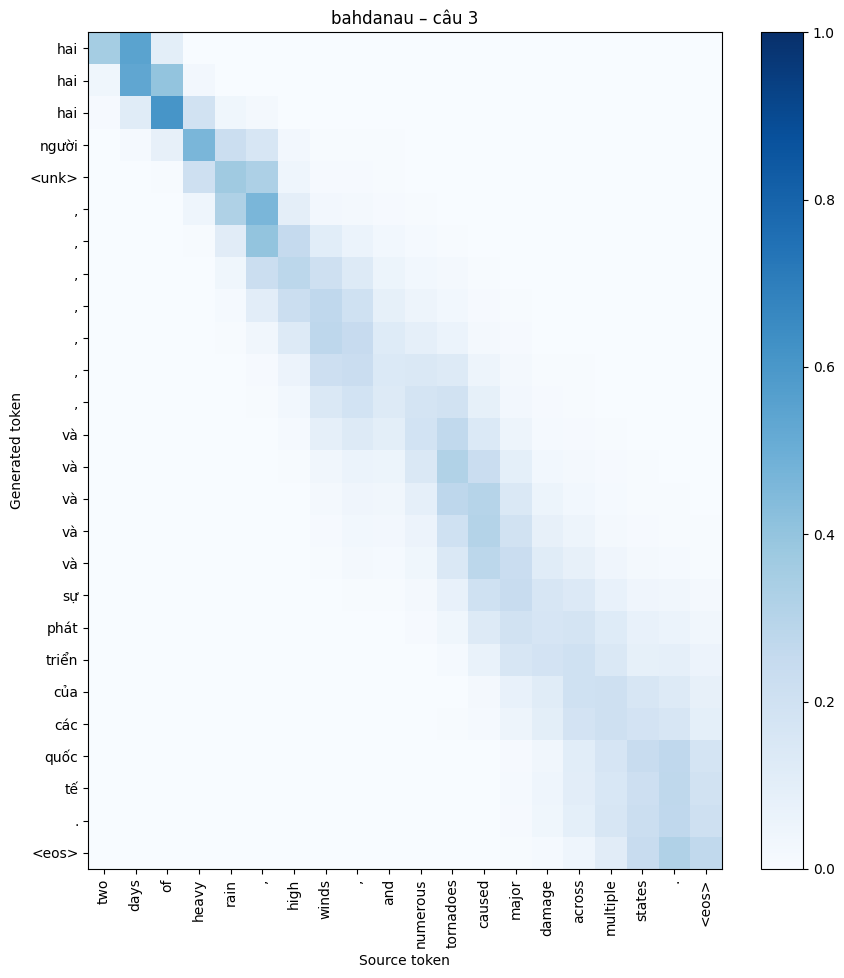

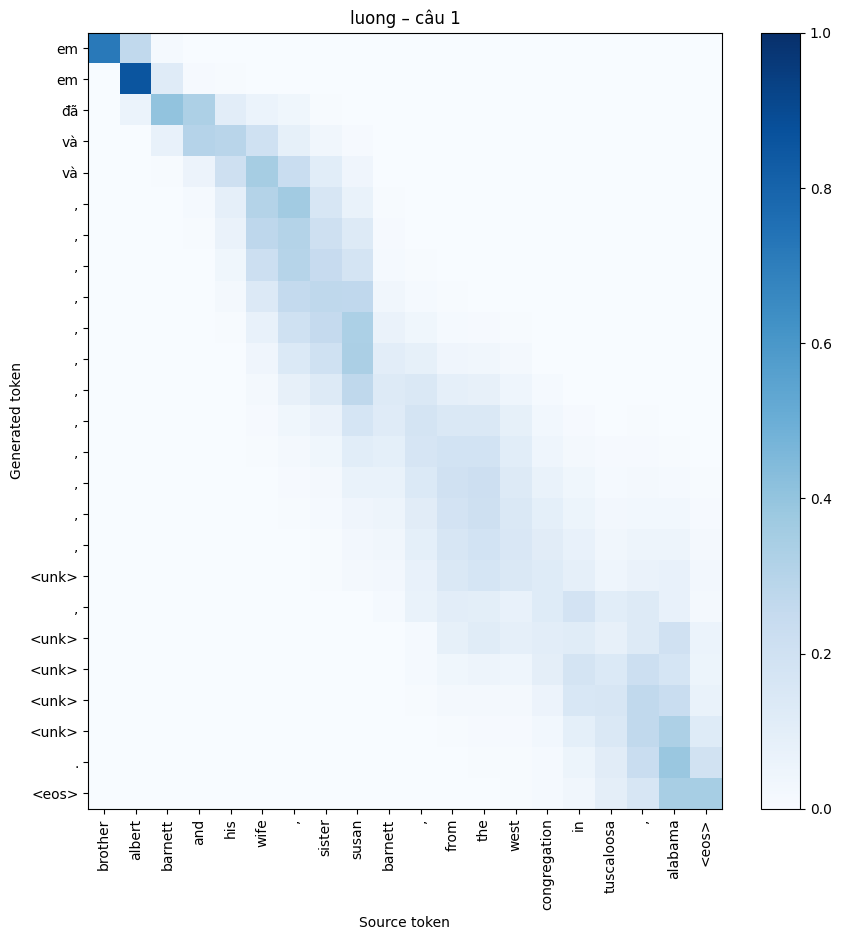

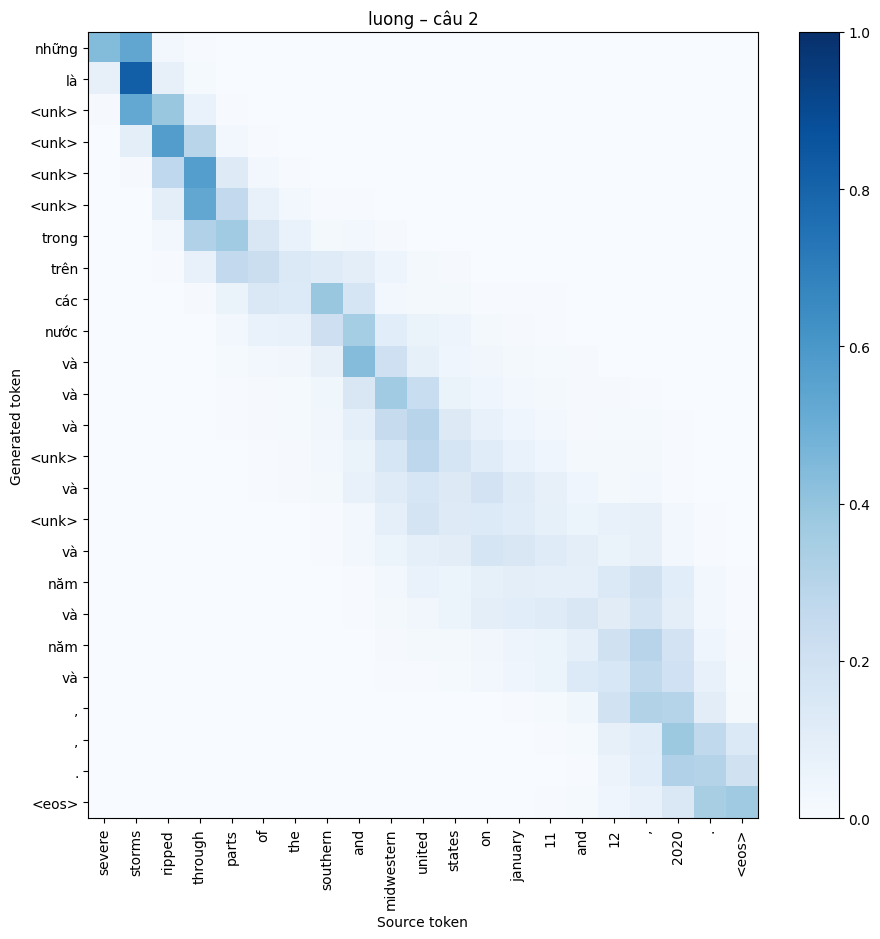

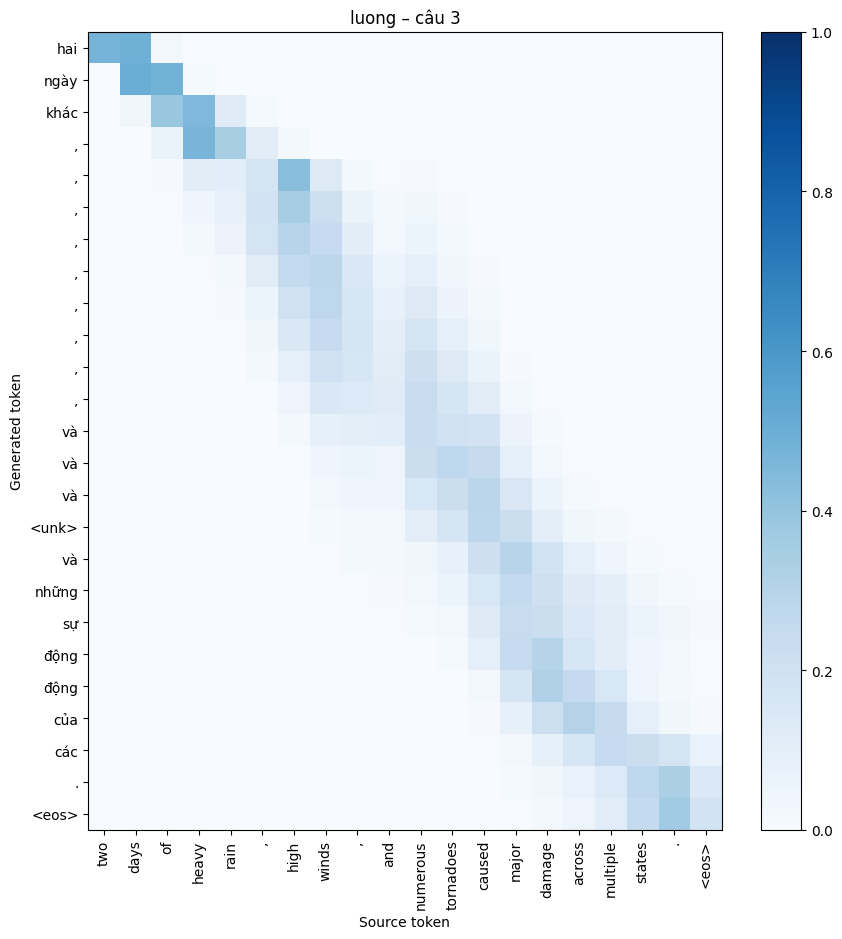

In [17]:
# Heatmap cho ba câu test: Bahdanau và Luong.
for name in ['bahdanau', 'luong']:
    for i, row in enumerate(filtered['test'][:3], 1):
        b = collate([row])
        ids, weights = generate(models[name], b['src'].to(device), b['lengths'],
                                cfg['max_words'] + 1)
        generated = ids[0].cpu().tolist()
        stop = generated.index(EOS) + 1 if EOS in generated else len(generated)
        matrix = weights[0, :stop, :b['lengths'][0]].cpu().numpy()
        x_labels = row['src'] + ['<eos>']
        y_labels = [tgt_itos[t] for t in generated[:stop]]
        fig, ax = plt.subplots(figsize=(max(6, len(x_labels) * 0.45),
                                         max(3, len(y_labels) * 0.38)))
        im = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=1, aspect='auto')
        ax.set_xticks(range(len(x_labels)), x_labels, rotation=90)
        ax.set_yticks(range(len(y_labels)), y_labels)
        ax.set_xlabel('Source token')
        ax.set_ylabel('Generated token')
        ax.set_title(f'{name} – câu {i}')
        fig.colorbar(im, ax=ax)
        plt.tight_layout()
        plt.savefig(ART / f'attention_{name}_{i}.png', dpi=150)
        plt.show()